In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Number of rows and columns: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of duplicate rows: 0

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
Pape

In [10]:
print("TotalCharges data type before conversion:")
print(df["TotalCharges"].dtype)

print("\nBlank TotalCharges entries:")
print((df["TotalCharges"].astype(str).str.strip() == "").sum())

print("\nCustomers with zero tenure:")
print((df["tenure"] == 0).sum())

TotalCharges data type before conversion:
object

Blank TotalCharges entries:
11

Customers with zero tenure:
11


In [11]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("TotalCharges data type after conversion:")
print(df["TotalCharges"].dtype)

print("\nMissing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

print("\nCustomers with zero tenure:")
display(df.loc[df["tenure"] == 0, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

TotalCharges data type after conversion:
float64

Missing TotalCharges after conversion:
11

Customers with zero tenure:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [12]:
numerical_cols = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numerical_cols.tolist())

print("\nSummary statistics:")
display(df[numerical_cols].describe().T)

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [13]:
stats_table = pd.DataFrame({
    "Mean": df[numerical_cols].mean(),
    "Median": df[numerical_cols].median(),
    "Variance": df[numerical_cols].var(),
    "Standard Deviation": df[numerical_cols].std(),
    "Skewness": df[numerical_cols].skew()
})

display(stats_table.round(3))

,Mean,Median,Variance,Standard Deviation,Skewness
SeniorCitizen,0.162,0.000,0.136,0.369,1.834
tenure,32.371,29.000,603.168,24.559,0.240
MonthlyCharges,64.762,70.350,905.411,30.090,-0.221
TotalCharges,2283.300,1397.475,5138252.407,2266.771,0.962


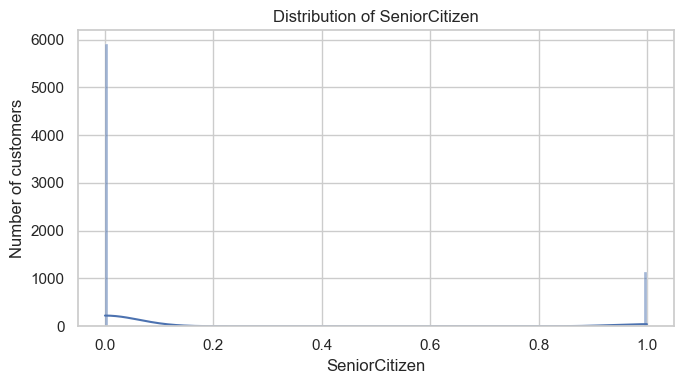

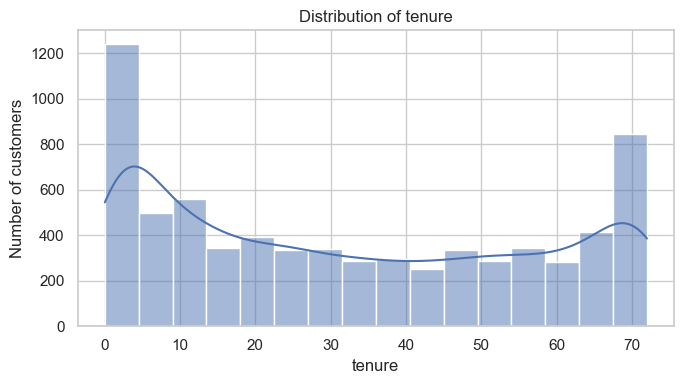

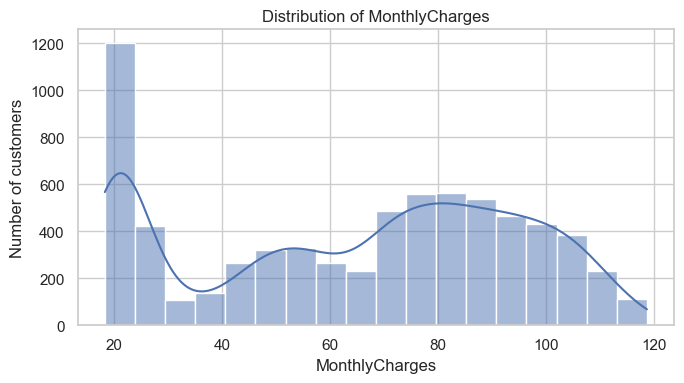

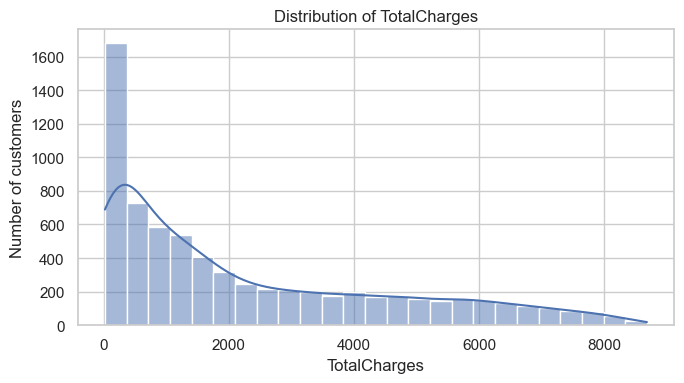

In [14]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of customers")
    plt.tight_layout()
    plt.show()

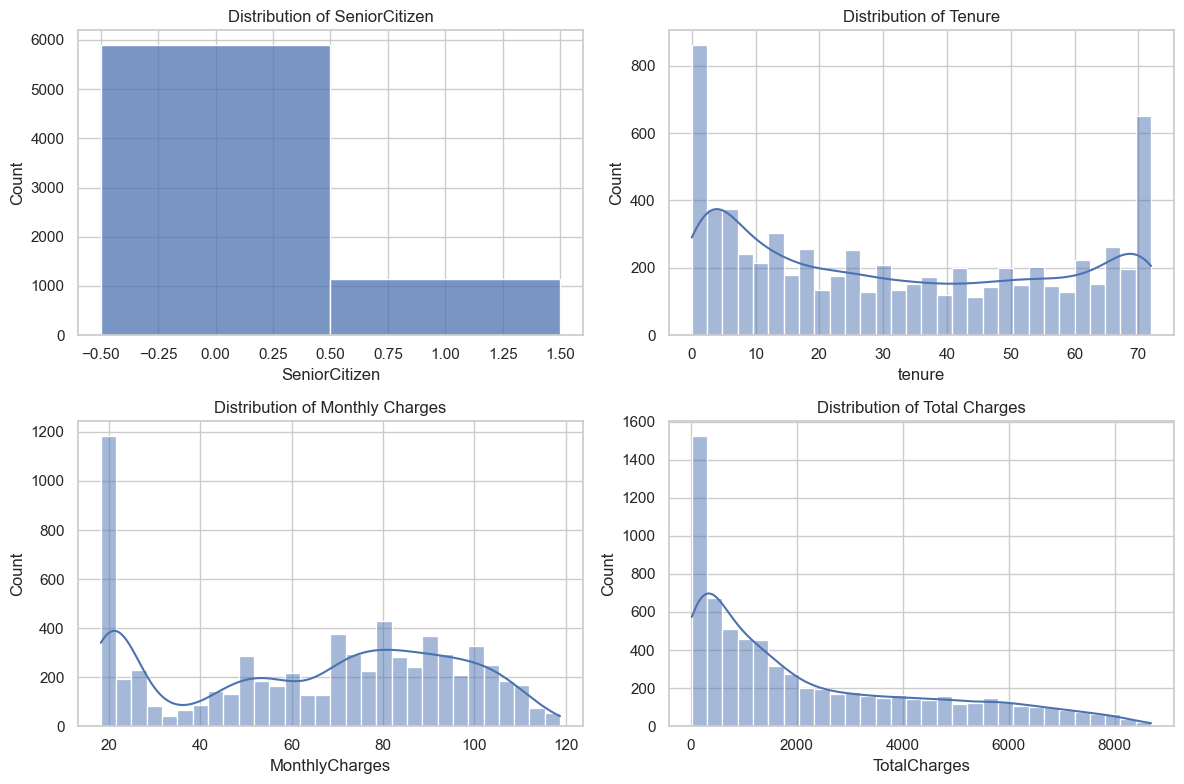

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["SeniorCitizen"], discrete=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of SeniorCitizen")

sns.histplot(df["tenure"], bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Tenure")

sns.histplot(df["MonthlyCharges"], bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Monthly Charges")

sns.histplot(df["TotalCharges"].dropna(), bins=30, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Distribution of Total Charges")

plt.tight_layout()
plt.show()

In [16]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

print("Churn counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn percentages:")
print(churn_percentages.round(2))

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


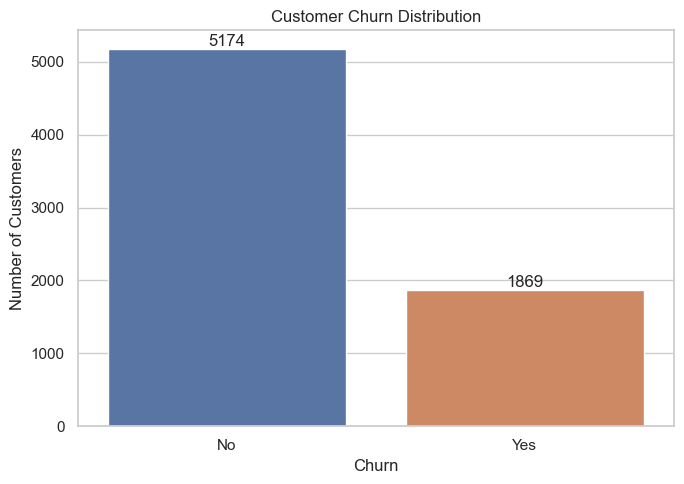

In [17]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Churn", hue="Churn", legend=False)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

In [18]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentage by contract type:")
display(contract_churn.round(2))

Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


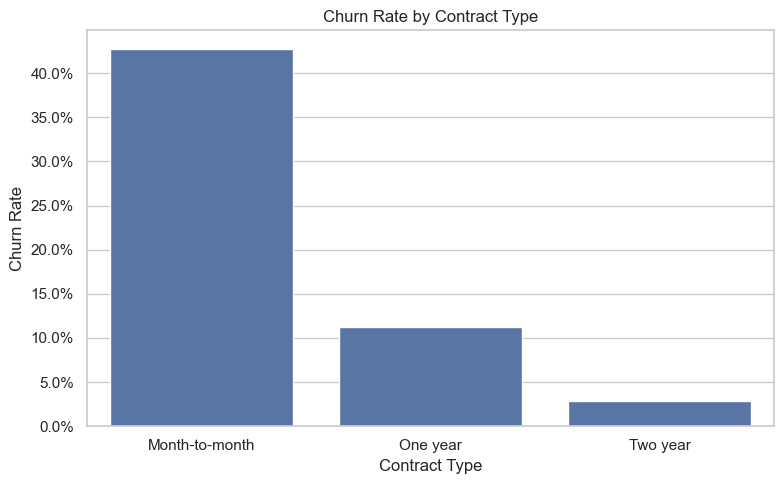

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int),
    errorbar=None
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.tight_layout()
plt.show()

In [20]:
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "std"]
)

display(tenure_summary.round(2))

,count,mean,median,std
Churn,,,,
No,5174,37.57,38.0,24.11
Yes,1869,17.98,10.0,19.53


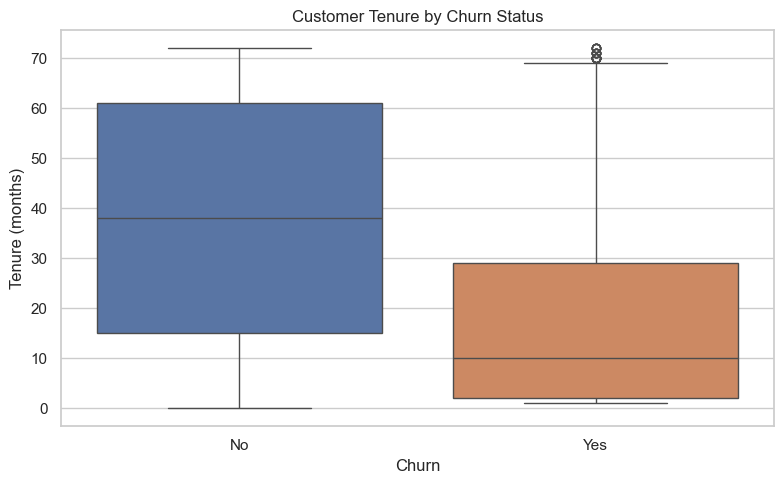

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    legend=False
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")

plt.tight_layout()
plt.show()

In [23]:
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "std"]
)

display(charges_summary.round(2))

,count,mean,median,std
Churn,,,,
No,5174,61.27,64.43,31.09
Yes,1869,74.44,79.65,24.67


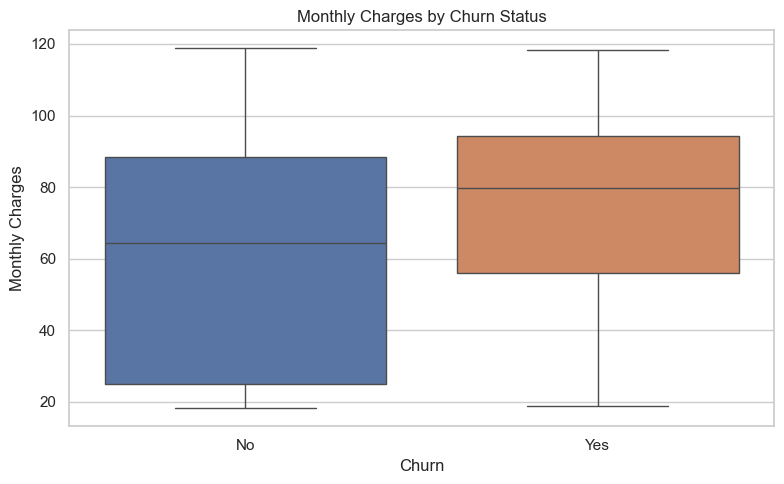

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [25]:

# Calculate churn rate for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by contract type:")
print(contract_churn.round(2))

Churn rate by contract type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


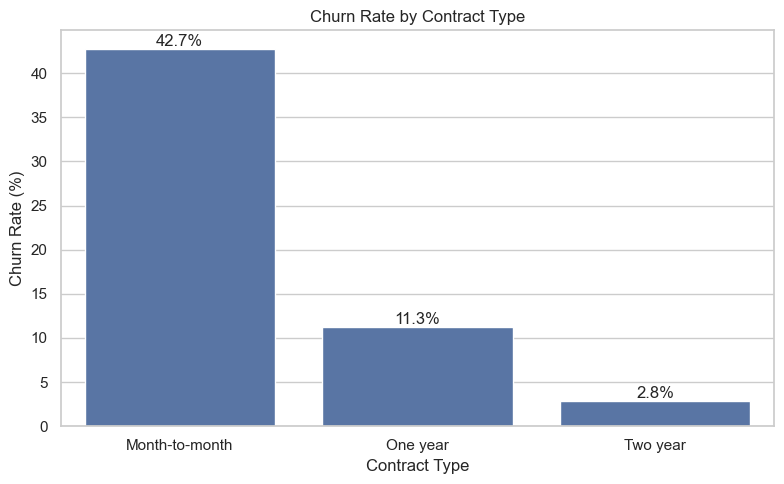

In [26]:
# Visualize churn rates
churn_rate = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .mul(100)
      .reset_index(name="ChurnRate")
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=churn_rate,
    x="Contract",
    y="ChurnRate"
)

ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


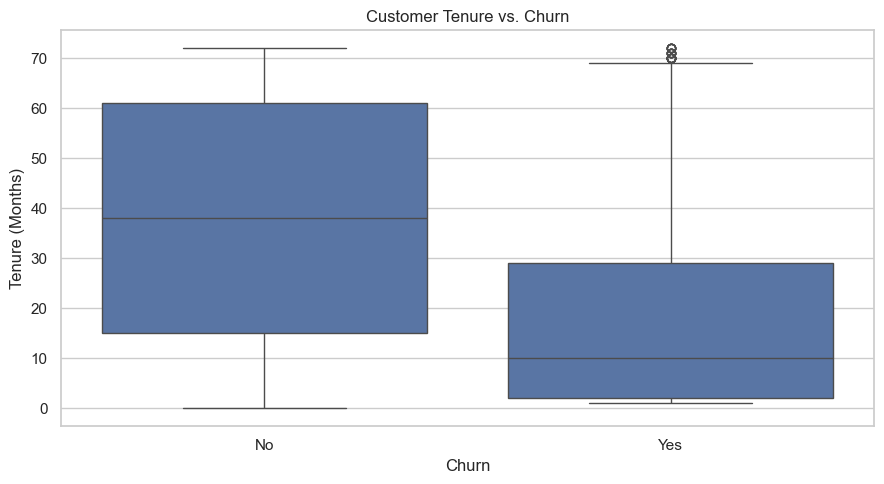

In [27]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs. Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [28]:
# Compare average and median tenure
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["mean", "median"]
)

print("Tenure summary by churn status:")
print(tenure_summary.round(2))

Tenure summary by churn status:
        mean  median
Churn               
No     37.57    38.0
Yes    17.98    10.0


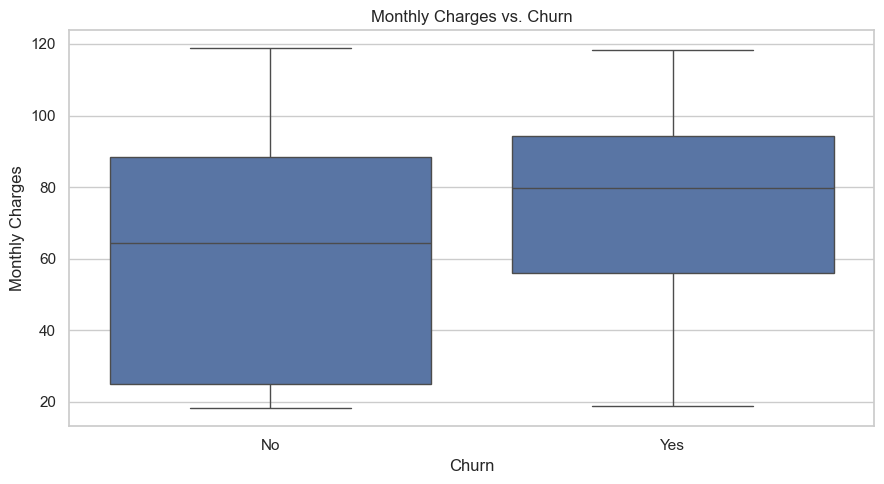

In [29]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs. Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [30]:
# Compare average and median monthly charges
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
)

print("Monthly charges by churn status:")
print(charges_summary.round(2))

Monthly charges by churn status:
        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


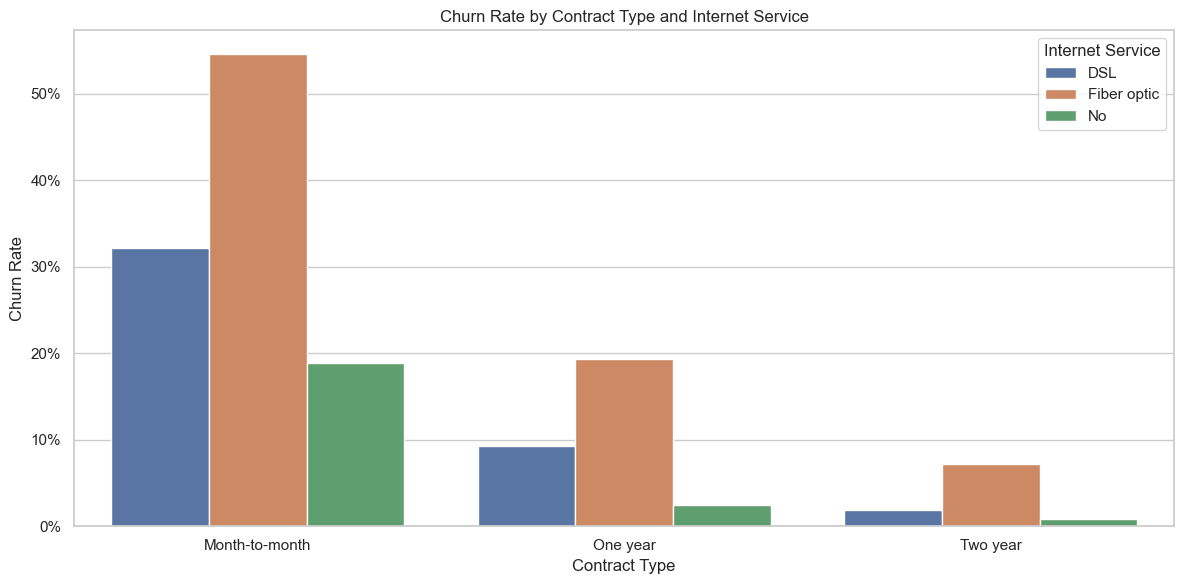

In [31]:
# Compare churn across contract types and internet services

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int),
    hue="InternetService",
    errorbar=None
)

plt.title("Churn Rate by Contract Type and Internet Service")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.legend(title="Internet Service")
plt.tight_layout()
plt.show()

In [32]:
# Select numerical variables
numerical_data = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

print("Correlation matrix:")
print(correlation_matrix.round(2))

Correlation matrix:
                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.02            0.22          0.10
tenure                   0.02    1.00            0.25          0.83
MonthlyCharges           0.22    0.25            1.00          0.65
TotalCharges             0.10    0.83            0.65          1.00


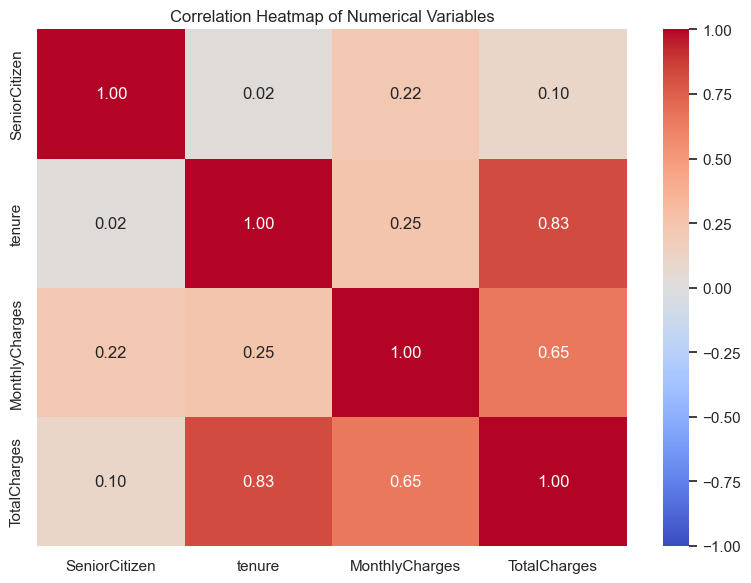

In [33]:
# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [56]:
# Examine the relationship between TotalCharges,
# tenure, and MonthlyCharges

print("Correlation of TotalCharges with other numerical features:")
print(
    df[["TotalCharges", "tenure", "MonthlyCharges"]]
    .corr()["TotalCharges"]
    .round(3)
)

print(
    "\nNote: TotalCharges is related to tenure and MonthlyCharges. "
    "It is not necessarily exactly equal to tenure * MonthlyCharges "
    "because customers may change plans or prices over time. "
    "Consider this relationship during future feature engineering."
)

Correlation of TotalCharges with other numerical features:
TotalCharges      1.000
tenure            0.826
MonthlyCharges    0.651
Name: TotalCharges, dtype: float64

Note: TotalCharges is related to tenure and MonthlyCharges. It is not necessarily exactly equal to tenure * MonthlyCharges because customers may change plans or prices over time. Consider this relationship during future feature engineering.


In [35]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)
# Calculate churn rates
tenure_contract_churn = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby(
          ["TenureGroup", "Contract"],
          observed=False
      )["ChurnFlag"]
      .mean()
      .mul(100)
      .reset_index(name="ChurnRate")
)

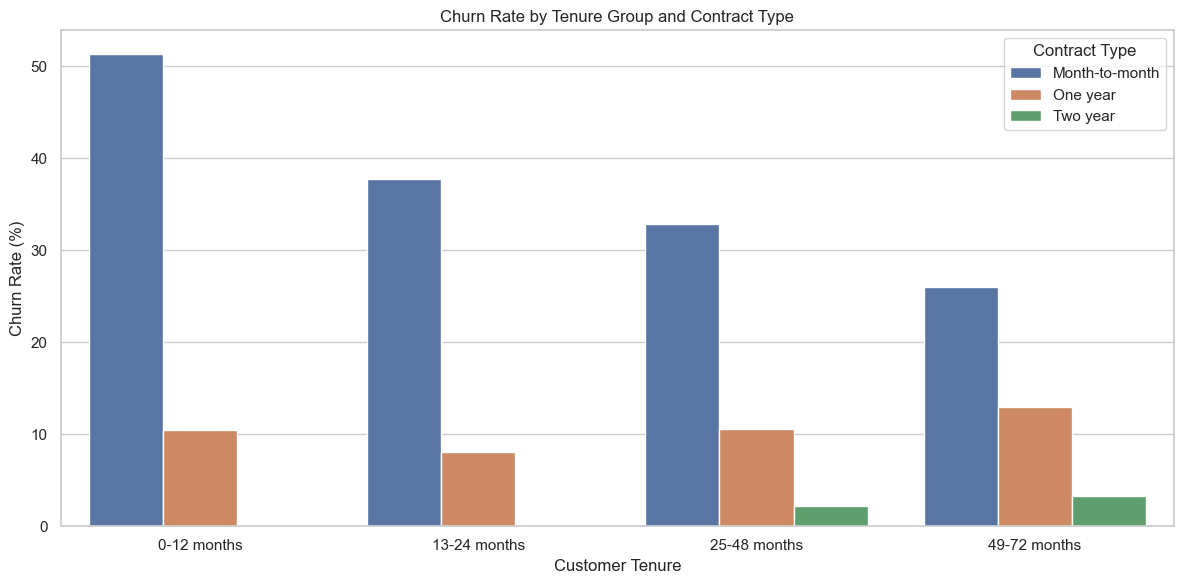

In [36]:
# Visualize
plt.figure(figsize=(12, 6))

sns.barplot(
    data=tenure_contract_churn,
    x="TenureGroup",
    y="ChurnRate",
    hue="Contract"
)

plt.title("Churn Rate by Tenure Group and Contract Type")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.legend(title="Contract Type")
plt.tight_layout()
plt.show()

In [37]:
# Identify potential outliers using the IQR method
outlier_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")


Column: tenure
Lower bound: -60.00
Upper bound: 124.00
Potential outliers: 0

Column: MonthlyCharges
Lower bound: -46.02
Upper bound: 171.38
Potential outliers: 0

Column: TotalCharges
Lower bound: -4688.48
Upper bound: 8884.67
Potential outliers: 0


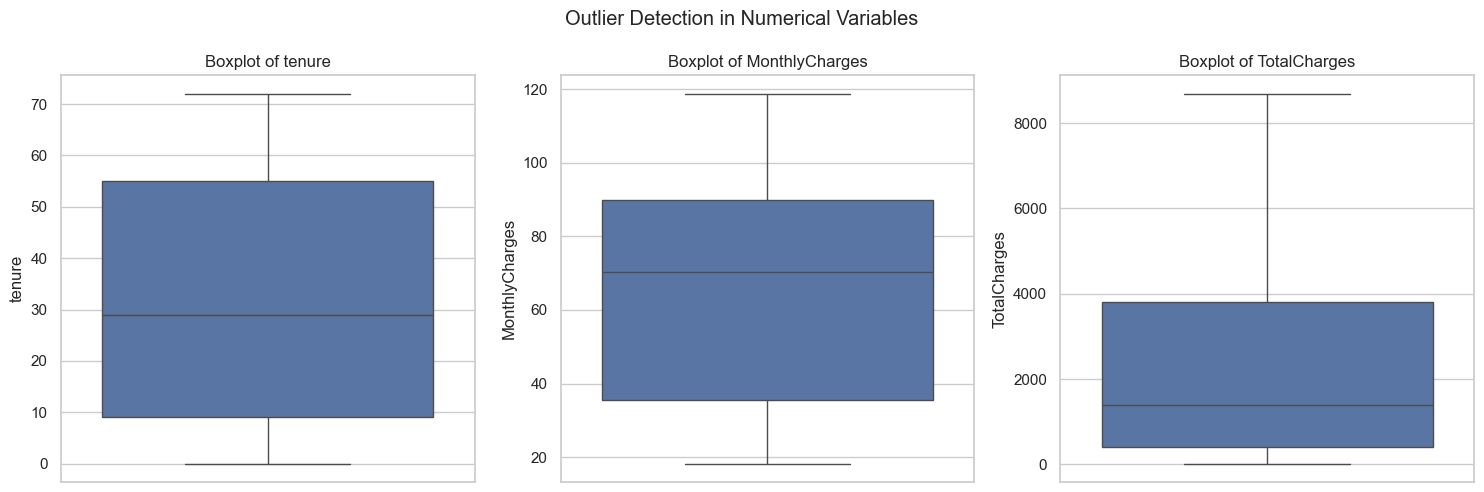

In [38]:
# Boxplots for numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(
    axes,
    ["tenure", "MonthlyCharges", "TotalCharges"]
):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)

plt.suptitle("Outlier Detection in Numerical Variables")
plt.tight_layout()
plt.show()

In [39]:
# Inspect the highest values in each numerical column
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    print(f"\nHighest values for {col}:")
    display(
        df.nlargest(5, col)[
            ["customerID", col, "Contract", "Churn"]
        ]
    )


Highest values for tenure:


,customerID,tenure,Contract,Churn
28,5248-YGIJN,72,Two year,No
35,6234-RAAPL,72,Two year,No
59,5954-BDFSG,72,Two year,No
62,0526-SXDJP,72,Two year,No
94,9848-JQJTX,72,Two year,No



Highest values for MonthlyCharges:


,customerID,MonthlyCharges,Contract,Churn
4586,7569-NMZYQ,118.75,Two year,No
2115,8984-HPEMB,118.65,Two year,No
3894,5989-AXPUC,118.60,Two year,No
4804,5734-EJKXG,118.60,One year,No
5127,8199-ZLLSA,118.35,One year,Yes



Highest values for TotalCharges:


,customerID,TotalCharges,Contract,Churn
4610,2889-FPWRM,8684.80,One year,Yes
4586,7569-NMZYQ,8672.45,Two year,No
6768,9739-JLPQJ,8670.10,Two year,No
5347,9788-HNGUT,8594.40,Two year,No
2187,8879-XUAHX,8564.75,Two year,No


In [40]:
print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values in TotalCharges:",
      df["TotalCharges"].isnull().sum())

print("\nInvalid tenure values:",
      ((df["tenure"] < 0) | (df["tenure"] > 72)).sum())

print("\nInvalid MonthlyCharges values:",
      (df["MonthlyCharges"] < 0).sum())

print("\nInvalid TotalCharges values:",
      (df["TotalCharges"].dropna() < 0).sum())

print("\nChurn categories:")
print(df["Churn"].value_counts())

Dataset shape: (7043, 22)

Duplicate rows: 0

Missing values in TotalCharges: 11

Invalid tenure values: 0

Invalid MonthlyCharges values: 0

Invalid TotalCharges values: 0

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [57]:
# Final dataset and churn summary

total_customers = len(df)
churn_count = (df["Churn"] == "Yes").sum()
retained_count = (df["Churn"] == "No").sum()

churn_rate = churn_count / total_customers * 100
retention_rate = retained_count / total_customers * 100

print("=" * 50)
print("TELCO CUSTOMER CHURN — FINAL SUMMARY")
print("=" * 50)

print(f"Total customers: {total_customers}")
print(f"Customers retained: {retained_count}")
print(f"Customers churned: {churn_count}")
print(f"Retention rate: {retention_rate:.2f}%")
print(f"Churn rate: {churn_rate:.2f}%")

print("\nDATA QUALITY")
print("-" * 50)
print("Duplicate rows:", df.duplicated().sum())
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TELCO CUSTOMER CHURN — FINAL SUMMARY
Total customers: 7043
Customers retained: 5174
Customers churned: 1869
Retention rate: 73.46%
Churn rate: 26.54%

DATA QUALITY
--------------------------------------------------
Duplicate rows: 0
Missing TotalCharges: 11


In [55]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict the majority class for every customer
X_baseline = df.drop(
    columns=["Churn", "customerID", "TenureGroup"],
    errors="ignore"
)
y_baseline = df["Churn"].map({"No": 0, "Yes": 1})

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_baseline, y_baseline)

baseline_predictions = baseline.predict(X_baseline)

# Evaluate the naive baseline
print("NAIVE MAJORITY-CLASS BASELINE")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_baseline, baseline_predictions):.4f}")
print(f"Precision: {precision_score(y_baseline, baseline_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_baseline, baseline_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_baseline, baseline_predictions, zero_division=0):.4f}")

NAIVE MAJORITY-CLASS BASELINE
-----------------------------------
Accuracy:  0.7346
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
